# SW_direct > solar constant on a steep west-facing slope

Minimal, synthetic reproduction of the spike in downscaled direct shortwave radiation that appears in the evening on
steep sun-facing slopes (see the discussion in the PR).

**Set-up.** One point, 30° slope facing west, seven hourly steps of a summer afternoon/evening at ~39°N, flat horizon.
ERA5 `ssrd` is the *accumulation over the previous hour*, while `SWtoa` (and `mu0`, the sun angle) is evaluated at the
time stamp. When the sun is setting, the hour-mean horizontal flux can therefore be larger than the instantaneous
top-of-atmosphere flux: `SW_direct > SWtoa`. That makes `ka` negative, and `SW_direct` is then multiplied by
`cos_illumination / mu0`, which is large on a slope facing a low sun.

The fix caps `SW_direct` at `SWtoa` before computing `ka`. Everything below runs the real `pt_downscale_radiations`.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import tempfile

sys.path.insert(0, '.')   # run from the tests/ folder
from synthetic_steep_point import make_case, expected_sw_direct, S0, SSRD_WM2, ZENITH_DEG
from TopoPyScale import topo_scale as ts

workdir = tempfile.mkdtemp()
row, ds_solar, horizon_da, meta, out_dir = make_case(workdir)
ts.pt_downscale_radiations(row, ds_solar, horizon_da, meta, out_dir)
out = xr.open_dataset(f'{workdir}/downscaled/down_pt_0.nc').load()

Downscaling LW, SW for point: 0


In [2]:
toa = ds_solar.SWtoa.values
sun = ~ds_solar.sunset.values
cos_i = np.clip(ds_solar.mu0.values * np.cos(row.slope) + np.sin(ds_solar.zenith.values) * np.sin(row.slope)
                * np.cos(ds_solar.azimuth.values - row.aspect), 0, None)
kt = np.clip(np.where(sun, SSRD_WM2 / np.where(toa > 0, toa, 1), 0), 0, 1)
kd = 0.952 - 1.041 * np.exp(-np.exp(2.3 - 4.702 * kt))
direct = SSRD_WM2 * (1 - kd)                                        # SW_direct on a horizontal surface, from ERA5
no_cap = np.where(sun, direct * cos_i / ds_solar.mu0.values.clip(1e-9), 0)   # what the code gave before the fix

pd.DataFrame({'zenith [deg]': ZENITH_DEG, 'SWtoa': toa.round(0), 'ssrd/3600': SSRD_WM2,
              'SW_direct before fix': no_cap.round(0), 'SW_direct (this code)': out.SW_direct.values.round(0)},
             index=ds_solar.time.values)

,zenith [deg],SWtoa,ssrd/3600,SW_direct before fix,SW_direct (this code)
2023-06-21 21:00:00,30.0,1186.0,900.0,789.0,789.0
2023-06-21 22:00:00,55.0,786.0,650.0,896.0,896.0
2023-06-21 23:00:00,70.0,469.0,400.0,820.0,820.0
2023-06-22 00:00:00,80.0,238.0,215.0,755.0,755.0
2023-06-22 01:00:00,85.0,119.0,160.0,1028.0,768.0
2023-06-22 02:00:00,88.0,48.0,110.0,1574.0,685.0
2023-06-22 03:00:00,89.5,12.0,0.0,0.0,0.0


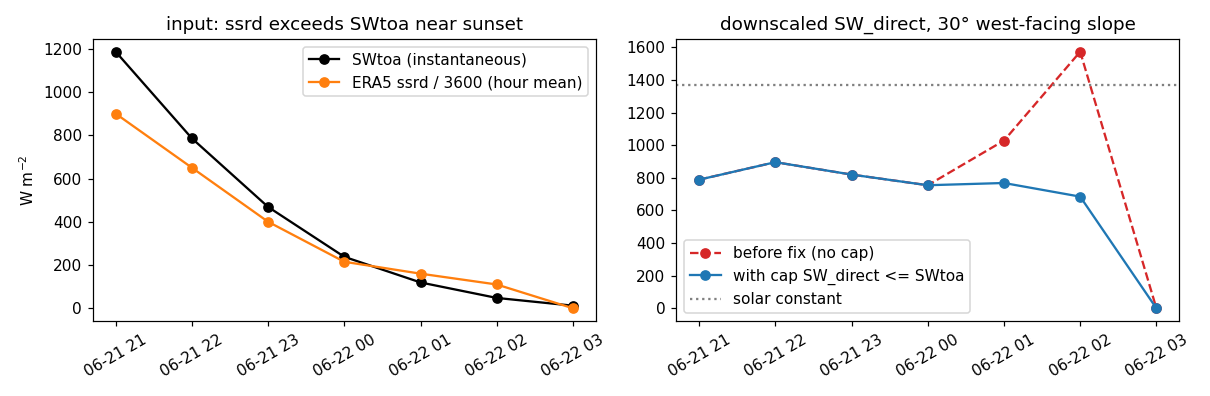

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
t = ds_solar.time.values
ax[0].plot(t, toa, 'k-o', label='SWtoa (instantaneous)')
ax[0].plot(t, SSRD_WM2, 'C1-o', label='ERA5 ssrd / 3600 (hour mean)')
ax[0].set_title('input: ssrd exceeds SWtoa near sunset'); ax[0].set_ylabel('W m$^{-2}$'); ax[0].legend()
ax[1].plot(t, no_cap, 'C3--o', label='before fix (no cap)')
ax[1].plot(t, out.SW_direct.values, 'C0-o', label='with cap SW_direct <= SWtoa')
ax[1].axhline(S0, color='grey', ls=':', label='solar constant')
ax[1].set_title('downscaled SW_direct, 30° west-facing slope'); ax[1].legend()
for a in ax: a.tick_params(axis='x', rotation=30)
fig.tight_layout()
assert out.SW_direct.max() <= S0 < no_cap.max()
np.testing.assert_allclose(out.SW_direct.values, expected_sw_direct(ds_solar, row), rtol=1e-3, atol=1e-2)